# Feature selection

Selection runs on raw data: no imputation, no scaling.

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from scipy import stats

from aml.data import load_data
from aml.features import constant_features
from aml.features import spread_stats


X_train, y_train, X_test = load_data()
print(X_train.shape, y_train.shape, X_test.shape)

(1212, 832) (1212,) (776, 832)


## Data overview

In [18]:
missing = X_train.isna().mean()
print(f"Missing: {missing.mean():.1%} overall, max per feature {missing.max():.1%}")

Missing: 7.6% overall, max per feature 10.0%


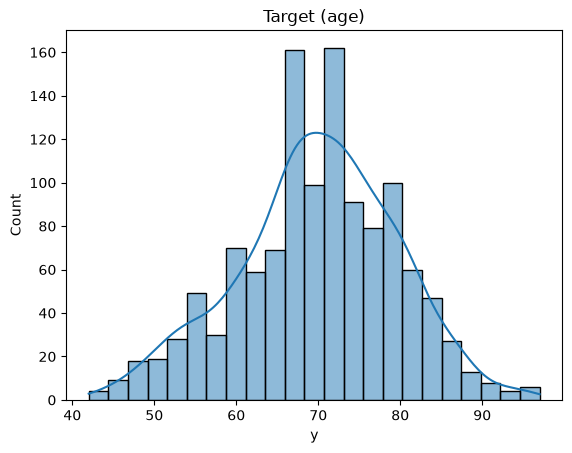

Skew -0.207, kurtosis -0.104


In [19]:
sns.histplot(y_train, kde=True)
plt.title("Target (age)")
plt.show()
print(f"Skew {stats.skew(y_train):.3f}, kurtosis {stats.kurtosis(y_train):.3f}")

## Step 1: constant features

Std of the non-null values, sorted highest to lowest. Raw std depends on each feature's units, so it is only for looking; the filter only drops constant features.

In [20]:
spread = spread_stats(X_train)
spread

,std,nunique,top_share,missing
x665,4.061152e+22,1132,0.000883,0.066007
x173,2.570333e+22,1131,0.000884,0.066832
x596,1.280957e+14,1109,0.000902,0.084983
x342,3.640997e+05,1099,0.000910,0.093234
x132,2.160821e+05,1110,0.000901,0.084158
...,...,...,...,...
x336,2.789179e-02,1125,0.000889,0.071782
x489,0.000000e+00,1,1.000000,0.082508
x530,0.000000e+00,1,1.000000,0.077558
x104,0.000000e+00,1,1.000000,0.068482


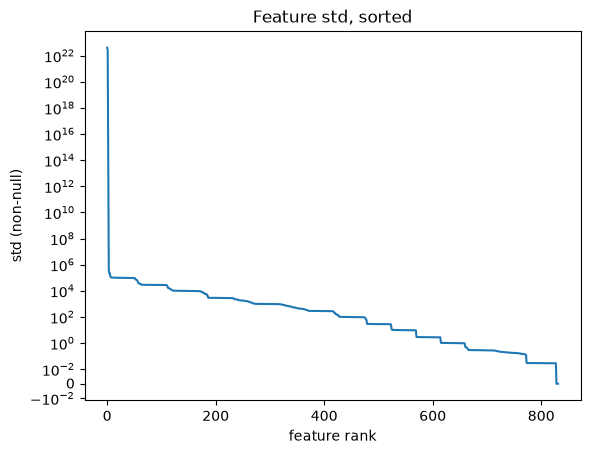

In [21]:
plt.plot(spread["std"].to_numpy())
plt.yscale("symlog", linthresh=1e-2)
plt.xlabel("feature rank")
plt.ylabel("std (non-null)")
plt.title("Feature std, sorted")
plt.show()

In [22]:
spread.sort_values("nunique").head(10)

,std,nunique,top_share,missing
x129,0.000000,1,1.000000,0.080858
x104,0.000000,1,1.000000,0.068482
x530,0.000000,1,1.000000,0.077558
x489,0.000000,1,1.000000,0.082508
x143,12.850896,444,0.595803,0.095710
x79,12123.578015,1091,0.000917,0.099835
x381,2731.345579,1093,0.000915,0.098185
x734,0.179810,1094,0.000914,0.097360
x313,2.816667,1094,0.000914,0.097360
x463,95820.858508,1095,0.000913,0.096535


In [23]:
constant = constant_features(X_train)
print(f"Dropping {len(constant)} constant features: {constant}")
X_step1 = X_train.drop(columns=constant)
X_step1.shape

Dropping 4 constant features: ['x104', 'x129', 'x489', 'x530']


(1212, 828)

## Step 3: RF permutation importance

Computed by `scripts/preprocessing_experiments.py` (slow, run on the HPC): `importance_all.csv` uses all rows, `importance_clean.csv` the rows left after outlier removal. `shadow_*` rows are shuffled copies of real features: a real feature should beat them.

In [24]:
imp = pd.read_csv("../outputs/importance_clean.csv", index_col=0)
is_shadow = imp.index.str.startswith("shadow_")
THRESHOLD = imp.loc[is_shadow, "mean"].max()  # best noise feature

selected = imp.index[(imp["mean"] > THRESHOLD) & ~is_shadow].tolist()
print(f"Threshold {THRESHOLD:.5f}: keeping {len(selected)} features")
imp.head(30)

Threshold 0.00026: keeping 91 features


,mean,std
x115,0.027353,0.005816
x415,0.015212,0.002412
x458,0.015199,0.002685
x507,0.013225,0.004178
x641,0.012537,0.002229
x159,0.012218,0.002809
x702,0.011293,0.002602
x334,0.006829,0.002447
x485,0.006483,0.002202
x194,0.006157,0.002231


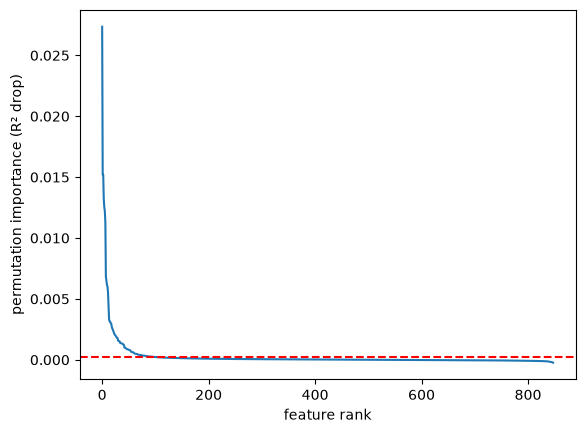

In [25]:
plt.plot(imp["mean"].to_numpy())
plt.axhline(THRESHOLD, color="red", linestyle="--")
plt.xlabel("feature rank")
plt.ylabel("permutation importance (R² drop)")
plt.show()